# Project Vyapaar | Notebook 02: Sales, Profit, Discounts & Customers 💰

**Team:** ____________________

**Lead for this part:** Member 2 (Business Analyst)

Which categories really make money, are discounts helping, and who are our best customers?

### How to run this notebook
**On Google Colab:**
1. Upload this notebook to Colab (File → Upload notebook).
2. Click **Runtime → Run all**.
3. When the "Choose Files" button appears, select the 4 data files: `orders.csv`, `products.csv`, `reviews.csv`, `marketing.csv`.

**On Jupyter (laptop):** keep the 4 csv files in the same folder as this notebook (or in a `data` folder next to it) and run all cells.

## Step 0: Load the data

In [1]:
import pandas as pd
import plotly.express as px
import os

# show numbers with 2 decimals and commas
pd.set_option("display.float_format", "{:,.2f}".format)
pd.set_option("display.max_columns", 30)

In [2]:
# This small function finds a csv file whether it is in this folder or in a "data" folder
def find_file(name):
    for folder in ["", "data/", "../data/"]:
        if os.path.exists(folder + name):
            return folder + name
    return None

# If the files are not there we are probably on Google Colab, so ask to upload them
if find_file("orders.csv") is None:
    from google.colab import files
    print("Please upload orders.csv, products.csv, reviews.csv and marketing.csv")
    files.upload()

In [3]:
# encoding="utf-8-sig" removes a hidden character at the start of orders.csv and reviews.csv
orders = pd.read_csv(find_file("orders.csv"), encoding="utf-8-sig")
products = pd.read_csv(find_file("products.csv"))
marketing = pd.read_csv(find_file("marketing.csv"))

# keep_default_na=False stops pandas from turning the word "None" into a blank.
# In reviews, "None" means "no complaint", so we want to keep it.
reviews = pd.read_csv(find_file("reviews.csv"), encoding="utf-8-sig", keep_default_na=False, na_values=[""])

print("orders:", orders.shape)
print("products:", products.shape)
print("reviews:", reviews.shape)
print("marketing:", marketing.shape)

orders: (4001, 14)
products: (121, 7)
reviews: (4001, 5)
marketing: (18, 9)


## Step 1: Clean the data
These are the same cleaning steps as **Notebook 01 (Data Cleaning)**. The reasons for each step are explained there.

In [4]:
# 1. remove exact duplicate rows
orders = orders.drop_duplicates()
products = products.drop_duplicates()
reviews = reviews.drop_duplicates()

# 2. fix the 2 wrongly labelled products
products.loc[products["product_id"] == "P011", "category"] = "Beauty"
products.loc[products["product_id"] == "P074", "subcategory"] = "Small Appliances"

# 3. fix spelling of sales channel
orders["sales_channel"] = orders["sales_channel"].replace("web site", "Website")

# 4. fill the 1 missing discount using: discount = 1 - revenue / (quantity x price)
orders["discount_pct"] = orders["discount_pct"].fillna(
    (1 - orders["revenue_inr"] / (orders["quantity"] * orders["unit_price_inr"])).round(2))

# 5. label blanks instead of deleting them
orders["customer_id"] = orders["customer_id"].fillna("Unknown")
orders["campaign_id"] = orders["campaign_id"].fillna("No campaign")

# 6. text -> dates
orders["order_date"] = pd.to_datetime(orders["order_date"])
marketing["start_date"] = pd.to_datetime(marketing["start_date"])
marketing["end_date"] = pd.to_datetime(marketing["end_date"])

# 7. join everything into one table
df = orders.merge(products, on="product_id").merge(reviews, on="order_id")
df["margin_%"] = df["profit_inr"] / df["revenue_inr"] * 100
print("Clean table:", df.shape)

Clean table: (4000, 25)


---
# Stage 2: The Business Mystery 💰
### 2.1 Big picture

In [5]:
total_revenue = df["revenue_inr"].sum()
total_profit = df["profit_inr"].sum()

print("Total revenue: ₹", round(total_revenue / 100000, 2), "lakh")
print("Total profit:  ₹", round(total_profit / 100000, 2), "lakh")
print("Profit margin:", round(total_profit / total_revenue * 100, 1), "%")

Total revenue: ₹ 175.95 lakh
Total profit:  ₹ 47.98 lakh
Profit margin: 27.3 %


### 2.2 Does high revenue mean high profit?

In [6]:
cat = df.groupby("category")[["revenue_inr", "profit_inr"]].sum()
cat["margin_%"] = cat["profit_inr"] / cat["revenue_inr"] * 100
cat["revenue_share_%"] = cat["revenue_inr"] / cat["revenue_inr"].sum() * 100
cat["profit_share_%"] = cat["profit_inr"] / cat["profit_inr"].sum() * 100
cat = cat.sort_values("revenue_inr", ascending=False)
cat

,revenue_inr,profit_inr,margin_%,revenue_share_%,profit_share_%
category,,,,,
Beauty,"5,270,516.45","2,143,754.23",40.67,29.95,44.68
Sports,"2,985,702.97","866,630.13",29.03,16.97,18.06
Home & Kitchen,"2,791,149.97","633,071.67",22.68,15.86,13.19
Electronics,"2,555,199.70","154,694.87",6.05,14.52,3.22
Office Supplies,"2,153,940.46","551,362.66",25.60,12.24,11.49
Fashion,"1,838,507.91","448,445.30",24.39,10.45,9.35


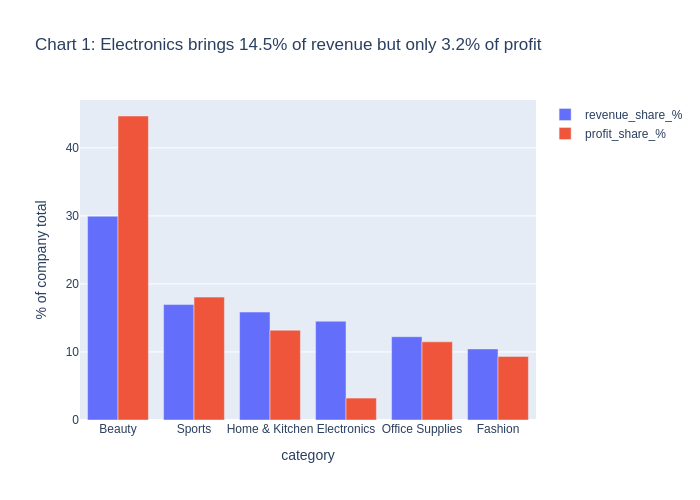

In [7]:
# CHART 1
chart1 = cat.reset_index()
fig = px.bar(chart1, x="category", y=["revenue_share_%", "profit_share_%"], barmode="group",
             title="Chart 1: Electronics brings 14.5% of revenue but only 3.2% of profit",
             labels={"value": "% of company total", "variable": ""})
fig.show()

In [8]:
# How many orders lost money in each category?
df[df["profit_inr"] < 0]["category"].value_counts()

category
Electronics        237
Sports              30
Home & Kitchen      28
Office Supplies     18
Name: count, dtype: int64

In [9]:
# Lowest margin subcategories
sub = df.groupby("subcategory")[["revenue_inr", "profit_inr"]].sum()
sub["margin_%"] = sub["profit_inr"] / sub["revenue_inr"] * 100
sub.sort_values("margin_%").head(5)

,revenue_inr,profit_inr,margin_%
subcategory,,,
Audio,"503,853.63","23,341.00",4.63
Smart Devices,"1,585,456.17","97,524.52",6.15
Mobile Accessories,"465,889.90","33,829.35",7.26
Small Appliances,"907,892.00","196,652.06",21.66
Cookware,"1,081,586.51","244,447.60",22.60


**So what?**
- **Beauty** is 30% of revenue but **45% of profit**. It is our best category.
- **Electronics** is 14.5% of revenue but only **3.2% of profit** (6.1% margin), and **237 Electronics orders lost money**.
- Why? Electronics is priced at only **1.22 × cost**, while Beauty is 1.92 × cost (see the mark-up check in Stage 1). So Electronics has very little room for discounts.

### 2.3 Are discounts helping?

In [10]:
disc = df.groupby("discount_pct").agg({"order_id": "count", "quantity": "mean", "revenue_inr": "sum", "profit_inr": "sum"})
disc.columns = ["orders", "avg_quantity", "revenue", "profit"]
disc["profit_per_order"] = disc["profit"] / disc["orders"]
disc["margin_%"] = disc["profit"] / disc["revenue"] * 100
disc

,orders,avg_quantity,revenue,profit,profit_per_order,margin_%
discount_pct,,,,,,
0.00,698,1.77,"3,562,855.47","1,336,837.67","1,915.24",37.52
0.05,633,1.75,"2,947,011.61","983,224.09","1,553.28",33.36
0.10,830,1.83,"3,985,593.04","1,181,223.87","1,423.16",29.64
0.15,548,1.79,"2,510,291.23","658,667.65","1,201.95",26.24
0.20,557,1.76,"2,258,136.82","469,981.24",843.77,20.81
0.30,444,1.78,"1,513,937.17","177,639.68",400.09,11.73
0.40,290,1.69,"817,192.12","-9,615.34",-33.16,-1.18


In [11]:
print("Correlation between discount and quantity:", round(df["discount_pct"].corr(df["quantity"]), 3))

Correlation between discount and quantity: -0.012


If discounts worked, people would buy **more units** when the discount is bigger. They don't:
- At **0%** discount people buy **1.77** units on average, and at **40%** they buy **1.69**. The correlation is almost **zero**.
- But profit per order drops from **₹1,915** to **−₹33**.

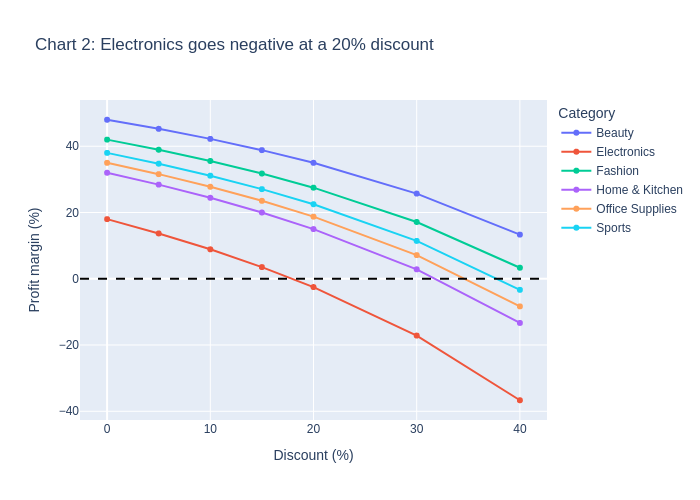

In [12]:
# CHART 2: margin at each discount level for each category
chart2 = df.pivot_table(index="discount_pct", columns="category", values="margin_%", aggfunc="mean")
chart2.index = chart2.index * 100   # 0.2 -> 20 (%)

fig = px.line(chart2, markers=True,
              title="Chart 2: Electronics goes negative at a 20% discount",
              labels={"discount_pct": "Discount (%)", "value": "Profit margin (%)", "category": "Category"})
fig.add_hline(y=0, line_dash="dash", line_color="black")
fig.show()

In [13]:
# What if Electronics discounts were capped at 10%?
# (assumption: people still buy the same quantity, which the table above supports)
elec = df[df["category"] == "Electronics"].copy()
elec["new_discount"] = elec["discount_pct"].clip(upper=0.10)
elec["new_profit"] = elec["quantity"] * elec["unit_price_inr"] * (1 - elec["new_discount"]) - elec["cost_inr"]

print("Electronics profit now: ₹", round(elec["profit_inr"].sum() / 100000, 2), "lakh")
print("With a 10% cap:         ₹", round(elec["new_profit"].sum() / 100000, 2), "lakh")

Electronics profit now: ₹ 1.55 lakh
With a 10% cap:         ₹ 3.06 lakh


In [14]:
# How much did we give away in discounts?
full_price_sales = (df["quantity"] * df["unit_price_inr"]).sum()
print("Discounts given in the year: ₹", round((full_price_sales - total_revenue) / 100000, 2), "lakh")

# Deep discounts (30% and 40%)
deep = df[df["discount_pct"] >= 0.30]
print("Orders at 30-40% discount:", len(deep), "=", round(len(deep) / len(df) * 100), "% of orders")
print("Their share of profit:", round(deep["profit_inr"].sum() / total_profit * 100, 1), "%")

Discounts given in the year: ₹ 27.99 lakh
Orders at 30-40% discount: 734 = 18 % of orders
Their share of profit: 3.5 %


In [15]:
# Which category gets the most deep discounts? (% of its orders at 30-40% off)
(deep["category"].value_counts() / df["category"].value_counts() * 100).sort_values(ascending=False)

category
Fashion           54.71
Sports            13.80
Electronics       13.60
Home & Kitchen    12.76
Beauty            11.68
Office Supplies   11.02
Name: count, dtype: float64

**So what?**
- The data **does not support** the current discount strategy. Bigger discounts don't make people buy more, they just lower our margin.
- We gave away **₹28 lakh** in discounts, more than half of our total profit (₹48 lakh).
- Orders at 30-40% off are 18% of orders but only **3.5% of profit**.
- Capping Electronics discounts at 10% would almost **double** Electronics profit (₹1.55 → ₹3.06 lakh).
- **55% of Fashion orders** are at 30-40% off, so Fashion is basically always on sale.

### 2.4 Customers
**Our definition of a high-value customer:** a customer in the **top 10% by total profit** in 2025. We use profit and not revenue, because revenue can hide loss-making orders.

In [16]:
known = df[df["customer_id"] != "Unknown"]
cust = known.groupby("customer_id").agg({"order_id": "count", "revenue_inr": "sum", "profit_inr": "sum"})
cust.columns = ["orders", "revenue", "profit"]

cutoff = cust["profit"].quantile(0.90)
high_value = cust[cust["profit"] >= cutoff]

print("Total customers:", len(cust))
print("High-value cut-off: ₹", round(cutoff), "profit")
print("High-value customers:", len(high_value))
print("Their average orders:", round(high_value["orders"].mean(), 1), "vs everyone:", round(cust["orders"].mean(), 1))
print("Their share of profit:", round(high_value["profit"].sum() / cust["profit"].sum() * 100, 1), "%")

Total customers: 599
High-value cut-off: ₹ 15161 profit
High-value customers: 60
Their average orders: 9.2 vs everyone: 6.7
Their share of profit: 23.5 %


In [17]:
print("Customers who bought more than once:", round((cust["orders"] > 1).mean() * 100, 1), "%")
print("Customers who bought 5 or more times:", round((cust["orders"] >= 5).mean() * 100, 1), "%")

Customers who bought more than once: 98.8 %
Customers who bought 5 or more times: 81.1 %


In [18]:
# When did each customer buy for the first time?
first_order = known.groupby("customer_id")["order_date"].min()
first_order.dt.quarter.value_counts().sort_index()

order_date
1    490
2     94
3     12
4      3
Name: count, dtype: int64

**So what?**
- **98.8%** of customers come back, so Vyapaar is a **repeat-customer business**. Keeping customers happy is the most important thing.
- The **60 high-value customers** order about **9 times** a year and bring **23.5% of profit**.
- **490 of 599** customers first bought in Q1. Only **15 new customers** joined in the second half of the year (Q3 + Q4). We look at this again in the marketing part.